# I-JEPA

An 8×8 digit is divided into sixteen 2×2 patches. A transformer predicts two held-out spatial blocks in the embedding space of a full-image target encoder.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")

## Tokenise the input

Tokens keep a fixed spatial order. Context and target positions are selected after tokenisation.

In [2]:
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split
from gallery.neural import seed_cpu
from gallery.representations import probe_encoders, update_teacher
from gallery.representations import PatchEncoder, MaskPredictor, train_masked, mask_test


def patchify(tensor):
    return tensor.reshape(-1, 4, 2, 4, 2).permute(0, 1, 3, 2, 4).reshape(-1, 16, 4)

## Predict hidden features

A full-view, stop-gradient target encoder supplies the targets. The online encoder sees visible tokens only. A separate predictor combines the context with learned mask tokens and positional embeddings.

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
X = patchify(torch.tensor(train))
T = patchify(torch.tensor(test))
encoder = PatchEncoder(X.shape[2], X.shape[1])
initial = copy.deepcopy(encoder)
predictor = MaskPredictor(X.shape[1])
teacher, history = train_masked(encoder, predictor, X, times=1, epochs=16)
mask_test(encoder, predictor, teacher, T, times=1)

Held-out masked latent MAE: 0.1208


## Probe a frozen encoder

A logistic probe is trained on the labelled training partition after self-supervision. The raw and random-feature baselines see the same examples.

Raw input: accuracy 0.969 | balanced accuracy 0.969 | macro F1 0.969
Random encoder: accuracy 0.980 | balanced accuracy 0.980 | macro F1 0.980


Trained encoder: accuracy 0.980 | balanced accuracy 0.980 | macro F1 0.980
Held-out mean feature SD: 0.1460 | Effective covariance rank: 19.19


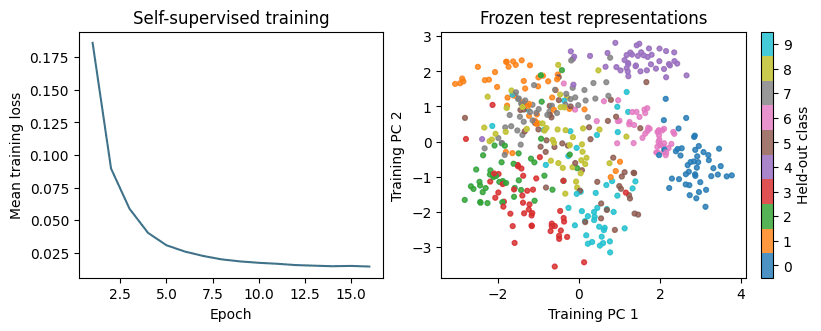

In [4]:
probe_encoders(initial, encoder, X, T, y, y_test, history)
plt.show()

## Reading the result

This CPU-scale adaptation uses one transformer layer and two disjoint block masks. The paper studies much larger inputs and training sets. Its benchmark results are a separate experiment.

## References

[Assran et al., Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture (2023)](https://arxiv.org/abs/2301.08243)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Frozen probes and masked-prediction training](../gallery/representations.py)